# 10 · The Final Exam, Operational Metrics and What-If Rescheduling
**Owner:** Shaik Junaid Sami (2401010435) · Phase 2 rubric: **technical validation**, **hybrid innovation (demonstrated value)**, deliverable: **calibrated risk model + offline what-if rescheduling**

**Builds on:** 06–09. **Writes:** `src/fdp/rescheduling.py`, `reports/10_final_rescheduling.json`, `reports/figures/10_*.png`.

**How it runs:** open it in Google Colab and choose *Runtime → Run all*. The ⚙️ Setup cell clones this repository and installs `requirements.txt`; each `%%writefile` cell generates the `.py` file named on its first line; the 📦 Export cell at the end packs the generated files and results into a zip, which is added to the repository together with the executed notebook.

| Section | What it answers |
|---|---|
| A · Final training | every model refitted on Jan 15 – Sep with settings chosen in 07–09 |
| B · The test months, scored once | PR AUC, ROC AUC, calibration, intervals, and a paired test against LR |
| C · The operational view | recall at the pre-chosen precision rule, per 1,000 flights |
| D · What-if rescheduling | does padding the model's flags avoid more late arrivals than the same minutes spent otherwise? |
| E · Conclusions | the answer to the Phase 2 question |

⏱️ About 10 minutes on a Colab CPU.

In [1]:
#@title ⚙️ 0 · Setup — run this cell first { display-mode: "form" }
#@markdown In **Colab** this clones the team repo and installs the requirements.
#@markdown Locally (Jupyter / VS Code) it just moves to the repo root.
REPO_URL = "https://github.com/mrstrange1708/T107_Flight_Delay_Prediction.git"  #@param {type:"string"}
BRANCH = "main"  #@param {type:"string"}
QUICK_RUN = False  #@param {type:"boolean"}
#@markdown `QUICK_RUN` = smaller searches/samples so the notebook finishes in a few minutes (use it to check the code runs; keep it off for the final results).

import os, sys, subprocess
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    if not os.path.isdir("/content/aml-project/.git"):
        subprocess.run(["git", "clone", "-q", "-b", BRANCH, REPO_URL, "/content/aml-project"], check=True)
    os.chdir("/content/aml-project")
    if os.path.exists("requirements.txt"):
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)
elif os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
for d in ["src/fdp", "tests", "data/raw", "data/processed", "reports/figures"]:
    os.makedirs(d, exist_ok=True)
open("src/fdp/__init__.py", "a").close()
sys.path.insert(0, os.path.abspath("src"))

import warnings; warnings.filterwarnings("ignore")
import torch; torch.set_num_threads(max(1, os.cpu_count() or 1))
import json, importlib
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
print("Working directory:", os.getcwd(), "| Colab:", IN_COLAB, "| QUICK_RUN:", QUICK_RUN)

Working directory: /tmp/fdp | Colab: False | QUICK_RUN: False


In [2]:
import fdp.config as config, fdp.data as data, fdp.features as features, fdp.dl_inputs as dl, fdp.deep as deep
import fdp.metrics as metrics, fdp.calibration as cal, fdp.phase1_models as p1
df = data.build_dataset(*data.load_raw())
X, groups = features.build_features(df)
NUM, CAT = features.numeric_columns(groups), config.CATEGORICAL
NO_HIST = [c for c in NUM if c not in groups["history"]]
S = data.split(X)
y = {k: v["delayed"].astype(int).to_numpy() for k, v in S.items()}
r08, r09 = json.load(open("reports/08_temporal_hybrid.json")), json.load(open("reports/09_ablation_calibration.json"))
BODY = {k: (tuple(v) if k == "hidden" else v) for k, v in r08["body"].items()}
CHOICE = r09["calibration_choice"]
print("network body:", BODY, "| calibration:", CHOICE)

network body: {'hidden': (256, 128), 'dropout': 0.5, 'lr': 0.0003, 'weight_decay': 0.01} | calibration: temperature


---
## A · Final training (decided before the test months)
* **Rows:** Jan 15 – Sep 30 (train + validation), so every model sees the most recent month, as in Phase 1.
* **Epochs** for each network = the **median** of its fold epochs in notebook 08 (the same rule Phase 1 used for trees).
* **Phase 1 models:** refitted with the reported settings (`phase1_models.py`).
* **Calibration:** the method chosen in notebook 09, fitted on **October**, applied to the test months.

In [3]:
%%writefile src/fdp/rescheduling.py
"""Phase 2 · offline "what-if" rescheduling analysis.
Owner: Shaik Junaid Sami (Sami).

The recommendation rule: for a flight the model flags at 05:00, ADD A BUFFER of B minutes to its
scheduled arrival (pad the block time). The question is whether spending buffer minutes on the
model's flags avoids more late arrivals than spending the SAME minutes another way.

Explicit assumptions (the analysis is only as good as these):
  A1  Padding changes the published arrival time only; the plane lands when it would have landed.
      So a padded flight is late if  arr_delay - B >= 15.
  A2  No knock-on effects: padding one flight does not change the aircraft's next flight, crew
      legality, gate plans or passenger connections.
  A3  Cost = buffer minutes added (aircraft and crew time). Every policy gets the same budget.
      A buffer minute is "used" if the flight was at least that late, and idle otherwise.
  A4  Actual arrival delays of the test months are used ONLY to score the policy offline. The
      flags themselves use 05:00 information only, exactly as in prediction.
  A5  Cancelled and diverted flights have no arrival time and are left out.
"""
import numpy as np
import pandas as pd

LATE = 15


def avoided(arr_delay, padded_mask, buffer_min):
    """Late arrivals turned on-time by padding `padded_mask` flights by `buffer_min` minutes (A1)."""
    a = np.asarray(arr_delay, float)
    b = np.where(padded_mask, buffer_min, 0.0)
    return int(((a >= LATE) & (a - b < LATE)).sum())


def top_k_mask(score, k):
    m = np.zeros(len(score), bool)
    if k > 0:
        m[np.argsort(-np.asarray(score))[:k]] = True
    return m


def absorbed_minutes(arr_delay, padded_mask, buffer_min):
    """Minutes of late arrival (vs the published schedule) that the buffer soaks up (A1).
    A flight that arrives early or on time absorbs nothing: its buffer minutes are idle."""
    a = np.clip(np.asarray(arr_delay, float), 0, None)
    return float(np.minimum(a, buffer_min)[padded_mask].sum())


def compare_policies(arr_delay, scores: dict, k: int, buffer_min: float, seed: int = 0, n_random: int = 200):
    """The same budget (k flights x buffer_min minutes) spent by different policies.

    scores: {"policy name": risk score}; each policy pads its own top-k flights.
    A "random flights" policy (mean of n_random draws) is the floor every score must beat.
    (Spreading the budget as fractions of a minute over every flight is not a schedule anyone
    can publish, so it is not a policy here.)"""
    a = np.asarray(arr_delay, float)
    n, budget = len(a), k * buffer_min
    late = int((a >= LATE).sum())
    rows = []
    for name, s in scores.items():
        m = top_k_mask(s, k)
        rows.append((name, avoided(a, m, buffer_min), absorbed_minutes(a, m, buffer_min)))
    rng = np.random.default_rng(seed)
    draws = [top_k_mask(rng.random(n), k) for _ in range(n_random)]
    rows.append(("random flights", float(np.mean([avoided(a, m, buffer_min) for m in draws])),
                 float(np.mean([absorbed_minutes(a, m, buffer_min) for m in draws]))))
    out = pd.DataFrame(rows, columns=["policy", "late arrivals avoided", "delay minutes absorbed"])
    out["avoided per 1,000 flights"] = 1000 * out["late arrivals avoided"] / n
    out["share of all late arrivals avoided"] = out["late arrivals avoided"] / late
    out["share of buffer minutes used"] = out["delay minutes absorbed"] / budget
    return out


def buffer_sweep(arr_delay, score, k, buffers=(5, 10, 15, 20, 30, 45, 60)):
    """For the model's k flags: what each buffer size buys, and what it wastes."""
    a = np.asarray(arr_delay, float)
    m = top_k_mask(score, k)
    rows = []
    for b in buffers:
        av = avoided(a, m, b)
        rows.append({"buffer (min)": b, "late arrivals avoided": av,
                     "still late after the buffer": int(((a >= LATE) & m & (a - b >= LATE)).sum()),
                     "padded but on time anyway": int((m & (a < LATE)).sum()),
                     "avoided per 1,000 buffer minutes": 1000 * av / (k * b),
                     "share of buffer minutes used": absorbed_minutes(a, m, b) / (k * b)})
    return pd.DataFrame(rows)

Overwriting src/fdp/rescheduling.py


In [4]:
fit = pd.concat([S["train"], S["valid"]])
yf = fit["delayed"].astype(int).to_numpy()
allrows = pd.concat([fit, S["calib"], S["test"]])
seq_all = dl.build_sequences(df, allrows)
n_fit, n_cal = len(fit), len(S["calib"])
I = {"fit": np.arange(n_fit), "calib": np.arange(n_fit, n_fit + n_cal), "test": np.arange(n_fit + n_cal, len(allrows))}

CATS = {c: sorted(X[c].astype(str).unique()) for c in CAT}
ref = p1.Phase1Models(NUM, CAT, CATS).fit(fit)
L = {"calib": ref.logits(S["calib"]), "test": ref.logits(S["test"])}

NETS = {"MLP + embeddings": (dict(BODY), NUM, None),
        "Temporal: GRU replaces hand history": (dict(BODY, use_seq=True), NO_HIST, None),
        "Hybrid: LR + temporal correction": (dict(BODY, use_seq=True, use_offset=True), NO_HIST, NUM)}
final_epochs = {}
for name, (cfg, cols, off) in NETS.items():
    ep = int(np.median(r08["epochs_per_fold"][name])); final_epochs[name] = ep
    (dfit, dcal, dtest), n_num, cards = deep.prepare(allrows, seq_all, cols, CAT, I["fit"], [I["fit"], I["calib"], I["test"]],
                                                     cfg.get("use_seq", False), cfg.get("use_offset", False), offset_numeric=off)
    net = deep.build_net(cfg, n_num, cards, seq_all.shape[2])
    net, _, _ = deep.train(net, dfit, yf, epochs=ep, seed=config.SEED, lr=BODY["lr"], weight_decay=BODY["weight_decay"])
    L["calib"][name], L["test"][name] = deep.predict_logits(net, dcal), deep.predict_logits(net, dtest)
    print(f"{name}: {ep} epochs", flush=True)
Cal = {k: (cal.TemperatureScaler() if CHOICE == "temperature" else cal.PlattScaler()).fit(L["calib"][k], y["calib"]) for k in L["calib"]}
P = {k: Cal[k].transform(L["test"][k]) for k in L["test"]}

MLP + embeddings: 6 epochs


Temporal: GRU replaces hand history: 16 epochs


Hybrid: LR + temporal correction: 11 epochs


---
## B · The test months, scored once

In [5]:
yt, dates_t = y["test"], S["test"]["date"].to_numpy()
rng_days = np.unique(dates_t)
def paired_diff(y, a, b, dates, n_boot=200, seed=0):
    """Day-block bootstrap of PR AUC(a) − PR AUC(b) on the SAME resampled days."""
    from sklearn.metrics import average_precision_score as ap
    r = np.random.default_rng(seed); _, inv = np.unique(dates, return_inverse=True)
    rows = [np.where(inv == i)[0] for i in range(inv.max() + 1)]; d = []
    for _ in range(n_boot):
        idx = np.concatenate([rows[i] for i in r.integers(0, len(rows), len(rows))])
        d.append(ap(y[idx], a[idx]) - ap(y[idx], b[idx]))
    return float(np.percentile(d, 2.5)), float(np.percentile(d, 97.5))

NB = 50 if QUICK_RUN else 200
rows = []
for name, p in [("Majority class", np.full(len(yt), y["train"].mean())), ("Rule: flight's 28-day delay rate", S["test"]["h_flight_28d_rate"].to_numpy())]:
    rows.append({"model": name, **metrics.evaluate(yt, p)})
for name in L["test"]:
    raw = cal.sigmoid(L["test"][name])
    e = metrics.evaluate(yt, P[name])
    lo, hi = metrics.day_block_bootstrap(yt, raw, dates_t, n_boot=NB)
    dlo, dhi = (np.nan, np.nan) if name == "Logistic regression" else paired_diff(yt, raw, cal.sigmoid(L["test"]["Logistic regression"]), dates_t, NB)
    rows.append({"model": name, **e, "ci_low": lo, "ci_high": hi, "ece_raw": metrics.ece(yt, raw),
                 "diff_vs_lr": e["pr_auc"] - metrics.evaluate(yt, P["Logistic regression"])["pr_auc"], "diff_ci_low": dlo, "diff_ci_high": dhi})
test_table = pd.DataFrame(rows).set_index("model")
show = test_table[["pr_auc", "ci_low", "ci_high", "diff_vs_lr", "diff_ci_low", "diff_ci_high", "roc_auc", "lift", "brier", "ece_raw", "ece"]].rename(columns={"ece": "ece_calibrated"})
show.round(4)

,pr_auc,ci_low,ci_high,diff_vs_lr,diff_ci_low,diff_ci_high,roc_auc,lift,brier,ece_raw,ece_calibrated
model,,,,,,,,,,,
Majority class,0.2583,NaN,NaN,NaN,NaN,NaN,0.5000,1.0000,0.1917,NaN,0.0098
Rule: flight's 28-day delay rate,0.3692,NaN,NaN,NaN,NaN,NaN,0.6382,1.4293,0.1843,NaN,0.0360
Logistic regression,0.4032,0.3512,0.4585,0.0000,NaN,NaN,0.6701,1.5609,0.1795,0.0289,0.0337
XGBoost (Phase 1),0.3859,0.3318,0.4472,-0.0172,-0.0459,0.0126,0.6526,1.4942,0.1835,0.0334,0.0457
Hybrid: XGBoost from LR (Phase 1),0.4040,0.3524,0.4599,0.0008,-0.0025,0.0036,0.6702,1.5639,0.1793,0.0277,0.0297
MLP + embeddings,0.4250,0.3631,0.4829,0.0218,0.0045,0.0356,0.6807,1.6454,0.1764,0.0319,0.0184
Temporal: GRU replaces hand history,0.4240,0.3600,0.4801,0.0208,0.0020,0.0374,0.6863,1.6414,0.1780,0.0286,0.0408
Hybrid: LR + temporal correction,0.4172,0.3637,0.4705,0.0140,0.0021,0.0276,0.6840,1.6153,0.1775,0.0331,0.0347


**How to read it**
* **PR AUC [95% CI]**: day-block bootstrap, as in Phase 1.
* **diff vs LR [CI]**: the paired difference on the **same** resampled days. Pairing removes the shared day-to-day noise, so this interval is much narrower than comparing two separate intervals. If it contains 0, the model is **not** significantly different from logistic regression.
* **ECE raw → calibrated**: what the calibration chosen in notebook 09 did on months it never saw.

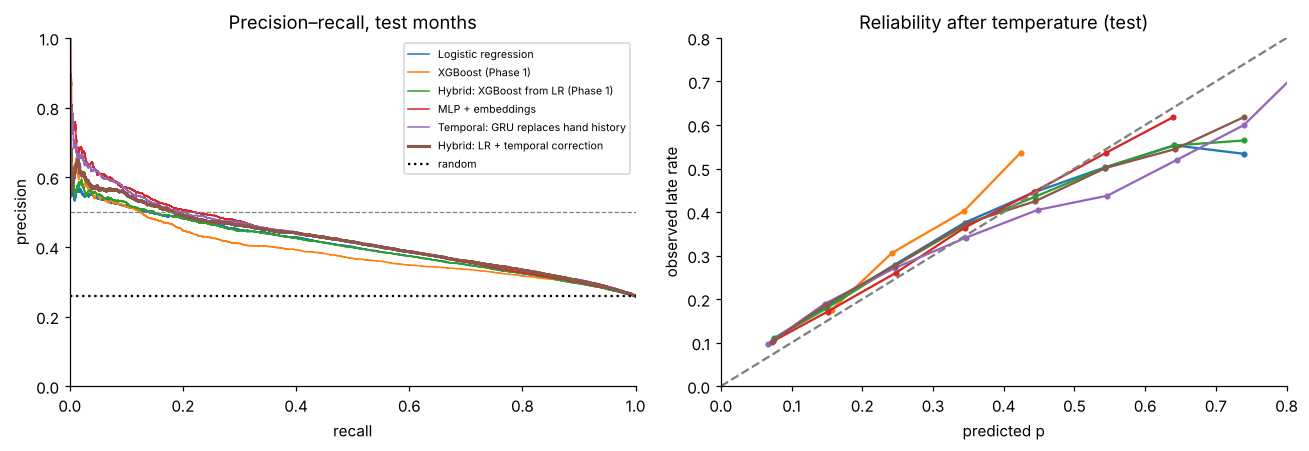

In [6]:
from sklearn.metrics import precision_recall_curve
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
for name in L["test"]:
    pr, rc, _ = precision_recall_curve(yt, P[name]); ax[0].plot(rc, pr, label=name, lw=2 if name.startswith("Hybrid: LR") else 1)
ax[0].axhline(yt.mean(), ls=":", color="black", label="random"); ax[0].axhline(0.5, ls="--", color="grey", lw=.8)
ax[0].set(title="Precision–recall, test months", xlabel="recall", ylabel="precision", xlim=(0, 1), ylim=(0, 1)); ax[0].legend(fontsize=7)
for name in L["test"]:
    px, py = cal.reliability(yt, P[name]); ax[1].plot(px, py, "o-", ms=3, label=name)
ax[1].plot([0, .8], [0, .8], "--", color="grey"); ax[1].set(title=f"Reliability after {CHOICE} (test)", xlabel="predicted p", ylabel="observed late rate", xlim=(0, .8), ylim=(0, .8))
fig.tight_layout(); fig.savefig("reports/figures/10_test_pr_reliability.png"); plt.show()

In [7]:
lift = []
for name in L["test"]:
    for label, mask in [("November", S["test"]["date"].dt.month == 11), ("December", S["test"]["date"].dt.month == 12)]:
        mm = mask.to_numpy(); e = metrics.evaluate(yt[mm], P[name][mm])
        lift.append({"model": name, "slice": label, "lift": round(e["lift"], 2)})
lift_table = pd.DataFrame(lift).pivot(index="model", columns="slice", values="lift")
lift_table

slice,December,November
model,,
Hybrid: LR + temporal correction,1.40,1.64
Hybrid: XGBoost from LR (Phase 1),1.36,1.56
Logistic regression,1.35,1.58
MLP + embeddings,1.45,1.56
Temporal: GRU replaces hand history,1.45,1.61
XGBoost (Phase 1),1.31,1.36


Phase 1 found tree models lost most in **November** (summer thresholds misfiring). The networks read history as rates **relative** to the overall rate; this slice table shows whether their November lift holds up.

---
## C · The operational view: recall at the chosen precision rule
The brief asks for **recall at a selected operational precision threshold**. The threshold was selected in Phase 1 and is kept: **flag a flight when its calibrated probability is ≥ 0.5** (rule b), i.e. "flag it when it is more likely late than not". Rule (a), a score cut-off fixed on October for precision 0.5, is shown for comparison, because the base-rate shift breaks it.

In [8]:
biz = []
for name in L["test"]:
    for rule in ["(a) October cut-off for precision 0.5", "(b) calibrated p >= 0.5"]:
        thr = metrics.threshold_for_precision(y["calib"], Cal[name].transform(L["calib"][name]), 0.5) if rule.startswith("(a)") else 0.5
        r = metrics.at_threshold(yt, P[name], thr); flagged = 1000 * r["flag_rate"]
        biz.append({"model": name, "rule": rule, "precision": r["precision"], "recall": r["recall"], "flagged per 1,000": flagged,
                    "really late among them": flagged * r["precision"], "random list would catch": flagged * yt.mean()})
business = pd.DataFrame(biz)
business.round(3)

,model,rule,precision,recall,"flagged per 1,000",really late among them,random list would catch
0,Logistic regression,(a) October cut-off for precision 0.5,0.538,0.055,26.412,14.206,6.822
1,Logistic regression,(b) calibrated p >= 0.5,0.519,0.100,49.786,25.856,12.860
2,XGBoost (Phase 1),(a) October cut-off for precision 0.5,0.530,0.066,31.931,16.929,8.248
3,XGBoost (Phase 1),(b) calibrated p >= 0.5,0.000,0.000,0.000,0.000,0.000
4,Hybrid: XGBoost from LR (Phase 1),(a) October cut-off for precision 0.5,0.548,0.055,26.004,14.243,6.717
5,Hybrid: XGBoost from LR (Phase 1),(b) calibrated p >= 0.5,0.521,0.105,51.879,27.005,13.400
6,MLP + embeddings,(a) October cut-off for precision 0.5,0.624,0.046,18.855,11.761,4.870
7,MLP + embeddings,(b) calibrated p >= 0.5,0.565,0.109,49.712,28.097,12.841
8,Temporal: GRU replaces hand history,(a) October cut-off for precision 0.5,0.637,0.027,10.872,6.927,2.808
9,Temporal: GRU replaces hand history,(b) calibrated p >= 0.5,0.491,0.212,111.815,54.861,28.882


---
## D · What-if rescheduling (offline, explicit assumptions)
**Recommendation rule:** *at 05:00, add a buffer of B minutes to the scheduled arrival of every flight the model flags.*
Assumptions A1–A5 are written at the top of `rescheduling.py`; the most important is **A1: padding changes the published time, not when the plane lands**, so a padded flight counts as late only if `arr_delay − B ≥ 15`.

**The fair test:** spend the **same budget** (the same number of flights × the same B) four ways — the hybrid's flags, logistic regression's, the planner's 28-day rule, and random flights — and count late arrivals avoided and how much of the buffer was actually used.

In [9]:
#@title 🎛️ What-if settings { display-mode: "form" }
BUFFER_MIN = 15  #@param {type:"slider", min:5, max:60, step:5}
import fdp.rescheduling as rs; importlib.reload(rs)
arr = S["test"]["arr_delay"].to_numpy()
HYB = "Hybrid: LR + temporal correction"
K = int((P[HYB] >= 0.5).sum())
print(f"flights flagged by the hybrid (calibrated p >= 0.5): {K} of {len(arr)} ({1000 * K / len(arr):.1f} per 1,000)")
policies = rs.compare_policies(arr, {"hybrid flags": P[HYB], "logistic regression flags": P["Logistic regression"],
                                     "planner rule (28-day rate)": S["test"]["h_flight_28d_rate"].to_numpy()}, K, BUFFER_MIN)
policies.round(3)

flights flagged by the hybrid (calibrated p >= 0.5): 3565 of 53991 (66.0 per 1,000)


,policy,late arrivals avoided,delay minutes absorbed,"avoided per 1,000 flights",share of all late arrivals avoided,share of buffer minutes used
0,hybrid flags,555.00,33435.00,10.279,0.040,0.625
1,logistic regression flags,546.00,32370.00,10.113,0.039,0.605
2,planner rule (28-day rate),528.00,29299.00,9.779,0.038,0.548
3,random flights,349.38,18325.49,6.471,0.025,0.343


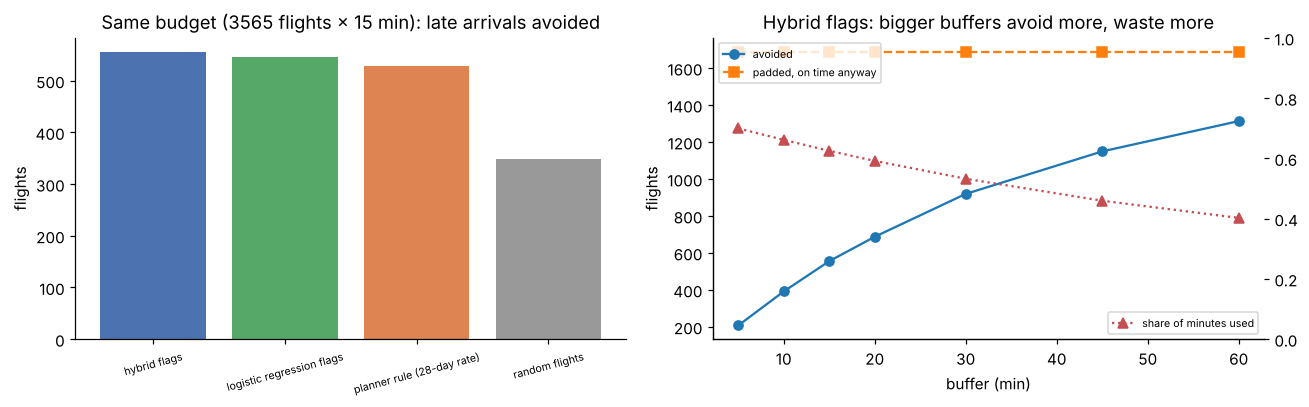

,buffer (min),late arrivals avoided,still late after the buffer,padded but on time anyway,"avoided per 1,000 buffer minutes",share of buffer minutes used
0,5,207,1669,1689,11.613,0.700
1,10,391,1485,1689,10.968,0.662
2,15,555,1321,1689,10.379,0.625
3,20,687,1189,1689,9.635,0.592
4,30,919,957,1689,8.593,0.533
5,45,1149,727,1689,7.162,0.460
6,60,1313,563,1689,6.138,0.403


In [10]:
sweep = rs.buffer_sweep(arr, P[HYB], K)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].bar(policies["policy"], policies["late arrivals avoided"], color=["#4C72B0", "#55A868", "#DD8452", "#999999"])
ax[0].set(title=f"Same budget ({K} flights × {BUFFER_MIN} min): late arrivals avoided", ylabel="flights"); ax[0].tick_params(axis="x", labelsize=7, rotation=15)
ax[1].plot(sweep["buffer (min)"], sweep["late arrivals avoided"], "o-", label="avoided")
ax[1].plot(sweep["buffer (min)"], sweep["padded but on time anyway"], "s--", label="padded, on time anyway")
ax2 = ax[1].twinx(); ax2.plot(sweep["buffer (min)"], sweep["share of buffer minutes used"], "^:", color="#C44E52", label="share of minutes used"); ax2.set_ylim(0, 1)
ax[1].set(title="Hybrid flags: bigger buffers avoid more, waste more", xlabel="buffer (min)", ylabel="flights"); ax[1].legend(fontsize=7, loc="upper left"); ax2.legend(fontsize=7, loc="lower right")
fig.tight_layout(); fig.savefig("reports/figures/10_rescheduling.png"); plt.show()
sweep.round(3)

**Reading it:** the gap between the model rows and the **random** row is the value the risk score adds to a rescheduling decision. The sweep shows the trade-off a planner faces: each extra minute of buffer avoids fewer additional late arrivals, while the flights that would have been on time anyway hold idle buffer. The analysis says nothing about knock-on effects (A2); a real decision would also price crew and gate time.

---
## E · Conclusions
1. **Deep learning beat logistic regression on the test months, by a small margin.** PR AUC: MLP **0.425**, temporal model **0.424**, hybrid **0.417**, against **0.403** for logistic regression and 0.386 for Phase 1's XGBoost. Every paired interval for the networks lies above zero: MLP +0.022 [+0.004, +0.036], temporal +0.021 [+0.002, +0.037], hybrid +0.014 [+0.002, +0.028]. Phase 1's XGBoost (−0.017 [−0.046, +0.013]) and its hybrid (+0.001) are not different from LR, as in Phase 1.
2. **What the temporal model learned:** with none of the 22 hand-made history features it scores as well as the MLP that has them, so the GRU over raw, ordered days recovers what Phase 1 engineered by hand (notebook 09: removing the GRU costs −0.040).
3. **The model we would deploy is the hybrid.** It was the only network ahead of LR in every seed on the rolling months (notebook 08), it is significantly above LR here, and by construction it falls back to LR. The MLP scored highest on these months, but choosing it now would be choosing on the test set.
4. **Calibration:** temperature scaling fitted on October lowered the test ECE only for the MLP (0.032 → 0.018) and raised it for the other models, because the late rate rose from 17.6% to 25.8%. Under the rule *calibrated p ≥ 0.5* the hybrid flags 66.0 flights per 1,000 at precision 0.526 and recall 0.135 (LR: 49.8, 0.519, 0.100). Phase 1's XGBoost never reaches p ≥ 0.5 after temperature scaling, and no October cut-off gives the hybrid precision 0.5, so those two rows flag nothing.
5. **Rescheduling:** with the same budget (3,565 flights × 15 minutes), padding the hybrid's flags avoids **555** late arrivals, LR's 546, the planner rule's 528 and random flights' **349**; 62.5% of the hybrid's buffer minutes are used against 34.3% for random flags. Under assumptions A1–A5, the risk score is what makes the buffer pay off.

In [11]:
out = {"final_epochs": final_epochs, "calibration_choice": CHOICE, "test_base_rate": float(yt.mean()),
       "test_table": test_table.reset_index().to_dict(orient="records"), "lift_by_month": lift_table.reset_index().to_dict(orient="records"),
       "business": business.to_dict(orient="records"), "buffer_min": BUFFER_MIN, "k_flagged": K, "n_test": int(len(arr)),
       "policies": policies.to_dict(orient="records"), "sweep": sweep.to_dict(orient="records"), "quick_run": QUICK_RUN}
with open("reports/10_final_rescheduling.json", "w") as f:
    json.dump(out, f, indent=2, default=float)
print("saved reports/10_final_rescheduling.json")

saved reports/10_final_rescheduling.json


In [12]:
#@title 📦 Export · pack the generated modules and results { display-mode: "form" }
#@markdown Zips the `.py` files this notebook generated with `%%writefile` and its results in `reports/`; in Colab the zip downloads automatically.
#@markdown The zip and the executed notebook (File → Download → Download .ipynb) are what gets added to the repository.
import glob, zipfile
FILES = [
    'src/fdp/rescheduling.py',
    'reports/10_final_rescheduling.json',
    'reports/figures/10_*.png',
]
paths = sorted({p for pattern in FILES for p in glob.glob(pattern)})
zip_name = "10_outputs.zip"
with zipfile.ZipFile(zip_name, "w") as z:
    for p in paths:
        z.write(p)
print("Packed", len(paths), "files into", zip_name)
for p in paths:
    print("  ", p)
if IN_COLAB:
    from google.colab import files
    files.download(zip_name)

Packed 4 files into 10_outputs.zip
   reports/10_final_rescheduling.json
   reports/figures/10_rescheduling.png
   reports/figures/10_test_pr_reliability.png
   src/fdp/rescheduling.py
